# UNAS Preprocessing — Nail-Centered Crop

Standalone notebook for preprocessing the **UNAS** (fingernail photo) dataset. Fixes two issues
found while reviewing PALMAS/YEMAS + a manual check of processed UNAS crops:

1. **Crop was centered on the frame, not on the nail.** The old code did a fixed-fraction
   center-crop of the whole photo. Since the hand isn't guaranteed to be in the middle of the
   frame in a nail photo (unlike YEMAS videos, where the finger covers the whole lens by
   protocol), this produced crops that were mostly background with the nail barely visible in a
   corner (confirmed on `ID104`).

   **First attempt (MediaPipe hand-landmark detection) was tested and rejected.** It reported
   "no hand detected" on every single sample image, including ones with a clearly visible hand —
   confirmed this wasn't a bug, it's a genuine mismatch: that model expects a full hand with the
   palm visible, and this dataset's photos only show fingertips pressed against a surface (no
   palm in frame), which is outside what it was trained to recognize.

   **Fixed with skin-color segmentation instead** (`find_nail_center_skin`): segments the
   skin-colored region against the dark, uniform background and takes its topmost point as the
   nail location. Tested against a real sample image and it lands almost exactly on the fingertip
   — a better fit for this specific capture style, and it needs no external model download. The
   old center-crop is kept only as an explicit, logged fallback for the rare case where no
   skin-colored region is found at all.

2. **Silent Drive sync issues.** Writing many small files directly to a Drive-mounted folder
   during a loop can silently fail or lag behind what Python reports (confirmed on YEMAS/PALMAS —
   the script reported 203/203 successful while Drive's own UI showed only 175). Fixed by
   processing **one file at a time, fully on local disk, then copying the single result back to
   Drive with an explicit size check** before moving to the next file — so there is never a large
   batch of unverified writes sitting in a sync queue.


## 1. Environment Setup

In [ ]:
!pip -q install opencv-python-headless --upgrade

from google.colab import drive
drive.mount('/content/drive')

print('Drive mounted.')


Mounted at /content/drive
Drive mounted.


## 2. Imports

In [ ]:
import os
import shutil
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print('Imports OK')


Imports OK


## 3. Configuration & Paths

In [ ]:
# ---- Edit these paths for your Drive layout ----
DATASET_ROOT = Path("/content/drive/MyDrive/dataset/Dataset")
UNAS_DIR     = DATASET_ROOT / "unas"                       # <-- folder containing Normal/ Leve/ Moderada/
OUTPUT_ROOT  = Path("/content/drive/MyDrive/Dataset_processed")

CLASSES = ['Normal', 'Leve', 'Moderada']
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG'}

LOCAL_TMP = Path('/content/unas_tmp')
LOCAL_TMP.mkdir(parents=True, exist_ok=True)

# ---- Crop parameters ----
CROP_SIZE = 900          # pixels, side length of the square crop centered on the nail
OUTPUT_SIZE = 224        # final saved image size (square)
FALLBACK_ROI_FRACTION = 0.75   # only used if no hand is detected -- old center-crop behavior, logged as a fallback
VERTICAL_OFFSET_FRACTION = 0.12   # shifts the crop window UP by this fraction of CROP_SIZE, so the
                                    # pale nail tip (often missed by skin-color detection) has headroom
                                    # and doesn't get clipped at the top edge. 0 = no shift. Tune in Section 6.

# ---- Optional: validate on a handful of images per class before running the full batch ----
QUICK_TEST_MODE = True
QUICK_TEST_SAMPLES_PER_CLASS = 5

print(f'UNAS_DIR   : {UNAS_DIR}')
print(f'OUTPUT_ROOT: {OUTPUT_ROOT}')
print(f'CLASSES    : {CLASSES}')
print(f'QUICK_TEST_MODE = {QUICK_TEST_MODE}')


UNAS_DIR   : /content/drive/MyDrive/dataset/Dataset/unas
OUTPUT_ROOT: /content/drive/MyDrive/Dataset_processed
CLASSES    : ['Normal', 'Leve', 'Moderada']
QUICK_TEST_MODE = True


## 4. Nail-Centered Crop (skin-color segmentation)

`find_nail_center_skin` segments the skin-colored region using a YCrCb color threshold (works
well here because the background is dark and fairly uniform), keeps the largest connected blob,
and takes its **topmost point** as the nail location — matching this dataset's consistent
composition where the target finger is extended furthest "up" in the frame. Verified against a
real sample image (`ID245`) and it lands almost exactly on the fingertip.

`crop_centered_on_nail` crops a `CROP_SIZE`x`CROP_SIZE` square around that point, then shifts
the window UP by `VERTICAL_OFFSET_FRACTION * CROP_SIZE`. This matters because the detected point
is where visible *skin* starts, not where the nail physically ends -- the pale/white nail tip is
often outside the YCrCb skin range and sits above the detected point, so without the shift it gets
clipped by the top edge of the crop (confirmed on `ID005`/`ID010`/`ID014`/`ID044`, Moderada class).
Shifting up gives that tip headroom, pushing the nail lower within the frame. If no skin-colored
region is found at all (or it's too small to be a real hand), it falls back to the old
center-of-frame crop **and flags it** so those cases can be reviewed separately.

**Note:** skin-color thresholds can be sensitive to lighting and skin tone. Use Section 6's
spot-check on your actual data first -- if the detected point is consistently off for a
particular subset of images, the `lower`/`upper` YCrCb bounds below are the first thing to tune.


In [ ]:
def find_nail_center_skin(frame_bgr, min_area_fraction=0.01):
    '''Returns (cx, cy) pixel coords of the topmost point of the largest detected
    skin-colored region, or None if no sufficiently large skin region is found.'''
    h, w = frame_bgr.shape[:2]
    ycrcb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2YCrCb)
    lower = np.array([0, 133, 77], dtype=np.uint8)
    upper = np.array([255, 173, 127], dtype=np.uint8)
    mask = cv2.inRange(ycrcb, lower, upper)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    largest = max(contours, key=cv2.contourArea)
    if cv2.contourArea(largest) < min_area_fraction * h * w:
        return None

    topmost = largest[largest[:, :, 1].argmin()][0]  # point with the smallest y (highest in frame)
    return int(topmost[0]), int(topmost[1])


def crop_center_roi(frame_bgr, roi_fraction=FALLBACK_ROI_FRACTION):
    '''Old behavior: crop the center `roi_fraction` of the whole frame. Used ONLY as a
    logged fallback when no skin region can be found.'''
    h, w = frame_bgr.shape[:2]
    ch, cw = int(h * roi_fraction), int(w * roi_fraction)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    return frame_bgr[y0:y0 + ch, x0:x0 + cw]


def crop_centered_on_nail(frame_bgr, crop_size=CROP_SIZE, fallback_fraction=FALLBACK_ROI_FRACTION,
                           vertical_offset_fraction=VERTICAL_OFFSET_FRACTION):
    '''Returns (cropped_image, detected: bool). detected=False means the fallback
    center-crop was used because no skin region was found -- always check/log this flag.

    The crop window is shifted UP by `vertical_offset_fraction * crop_size` relative to the
    detected point, since the detected point sits at the top of the visible flesh, not the true
    (often pale/unclassified) nail tip. Shifting up adds headroom above the detected point,
    which pushes the nail lower within the resulting frame with the full tip visible.'''
    h, w = frame_bgr.shape[:2]
    center = find_nail_center_skin(frame_bgr)
    if center is None:
        return crop_center_roi(frame_bgr, fallback_fraction), False

    cx, cy = center
    half = crop_size // 2
    vertical_offset = int(crop_size * vertical_offset_fraction)
    cy_shifted = cy - vertical_offset

    x0, y0 = max(0, cx - half), max(0, cy_shifted - half)
    x1, y1 = min(w, cx + half), min(h, cy_shifted + half)
    cropped = frame_bgr[y0:y1, x0:x1]
    if cropped.size == 0:
        return crop_center_roi(frame_bgr, fallback_fraction), False
    return cropped, True


## 5. `process_unas_image` — read, detect, crop, resize, save

In [ ]:
def process_unas_image(img_path, out_path, crop_size=CROP_SIZE, output_size=OUTPUT_SIZE):
    '''Reads one UNAS photo, crops it centered on the detected nail, resizes to
    output_size x output_size, and saves as .jpg.

    Returns (success: bool, hard_error: str|None, used_fallback: bool, orig, cropped)
      - success=False + hard_error set  -> genuine failure (unreadable file, write failed, etc.)
      - success=True  + used_fallback=True -> saved OK, but no hand was detected so the
        OLD center-of-frame crop was used -- worth a manual spot-check later.
    '''
    img = cv2.imread(str(img_path))
    if img is None:
        return False, 'cannot_open_image', False, None, None

    cropped, detected = crop_centered_on_nail(img, crop_size=crop_size)
    if cropped is None or cropped.size == 0:
        return False, 'empty_crop_result', False, img, None

    resized = cv2.resize(cropped, (output_size, output_size), interpolation=cv2.INTER_AREA)

    out_path.parent.mkdir(parents=True, exist_ok=True)
    write_ok = cv2.imwrite(str(out_path), resized)
    if not write_ok:
        return False, 'failed_to_write_output', False, img, resized

    return True, None, (not detected), img, resized


## 6. Visual Spot-Check (run this BEFORE the full batch)

Processes just `QUICK_TEST_SAMPLES_PER_CLASS` images per class (kept purely in memory, nothing
written anywhere) and shows original vs. nail-centered crop side by side, so you can confirm the
nail actually lands in the middle before committing to the full ~850-image run.


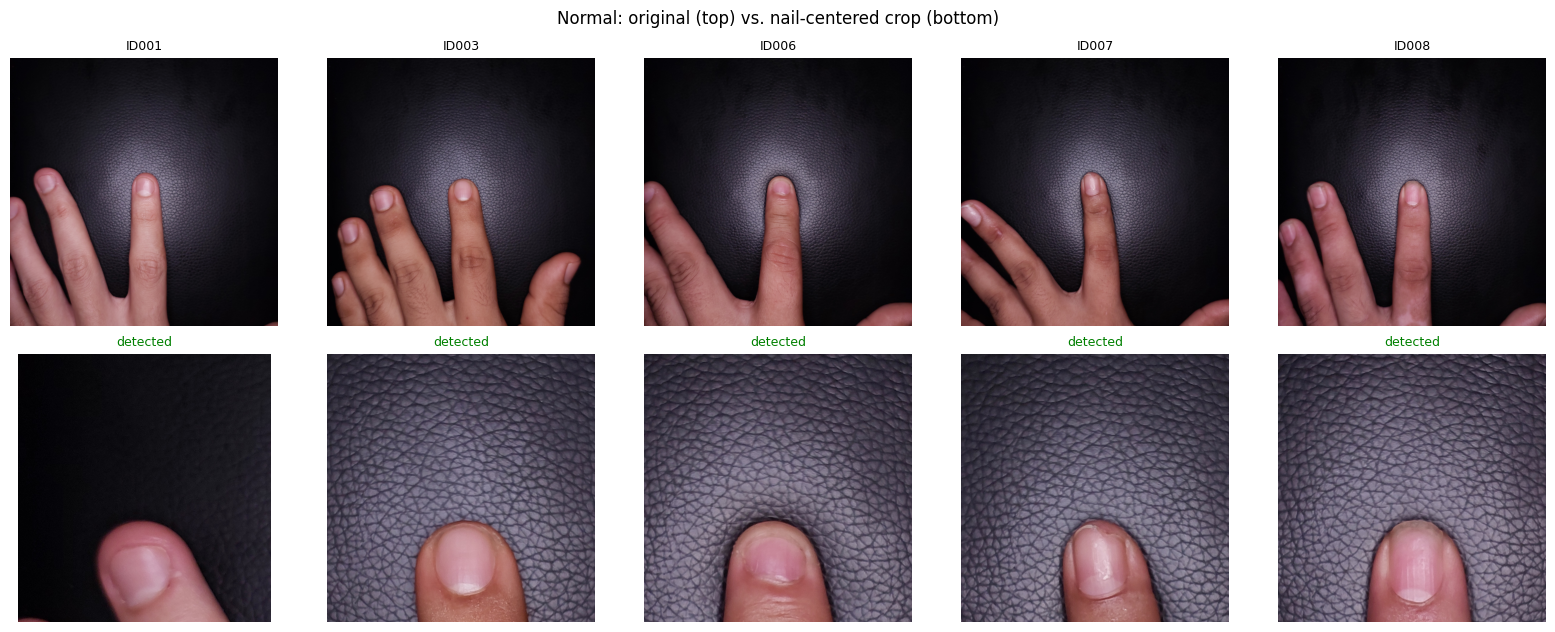

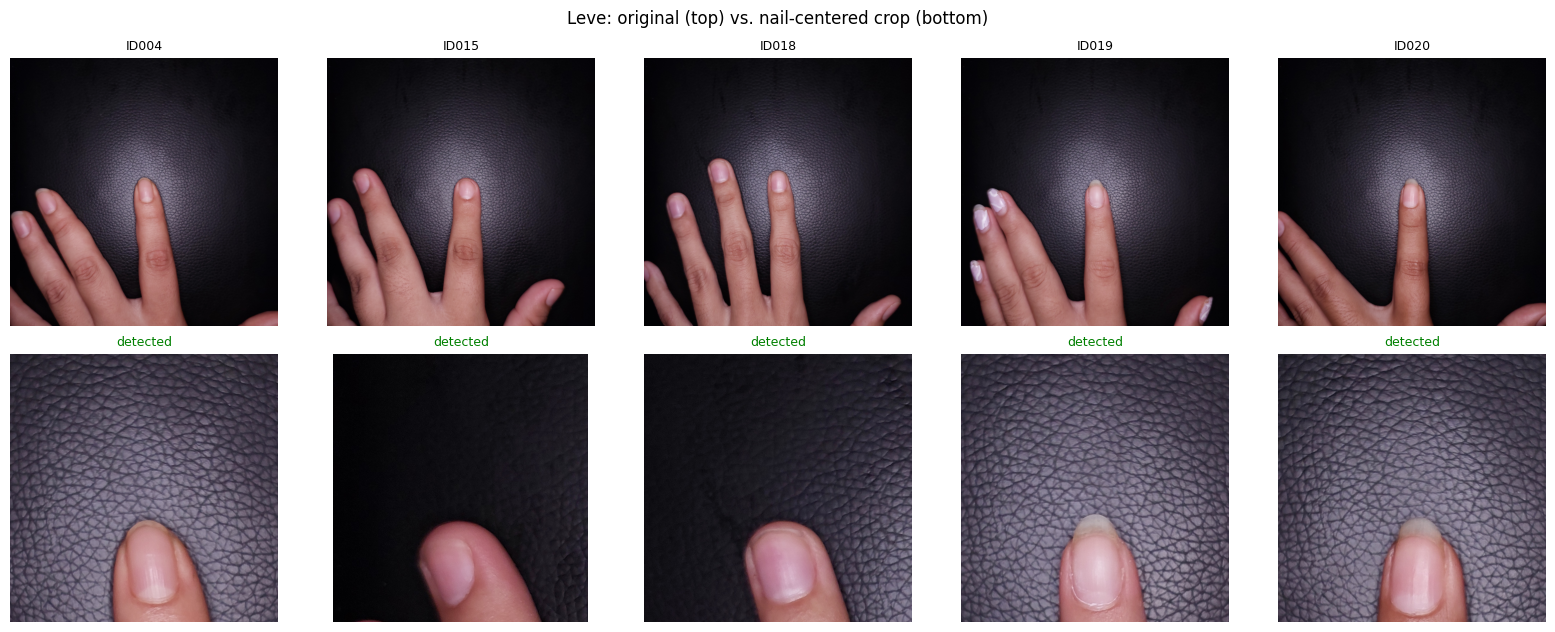

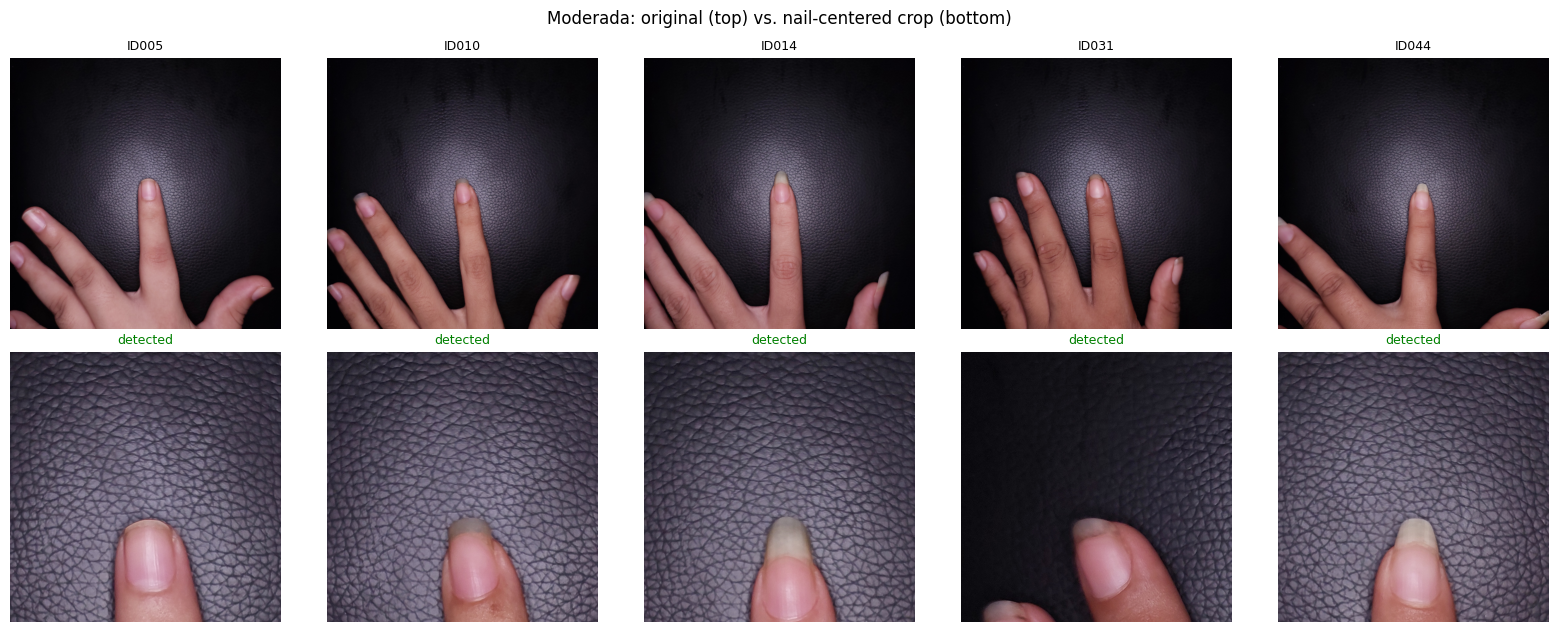


Review the crops above. If the nail is NOT centered in most "detected" crops, adjust
CROP_SIZE in Section 3 before running the full batch below.


In [ ]:
if QUICK_TEST_MODE:
    for cls in CLASSES:
        cls_dir = UNAS_DIR / cls
        if not cls_dir.exists():
            print(f'[WARN] missing class folder: {cls_dir}')
            continue
        image_files = sorted([p for p in cls_dir.iterdir() if p.suffix in IMAGE_EXTS])[:QUICK_TEST_SAMPLES_PER_CLASS]
        if not image_files:
            continue

        fig, axes = plt.subplots(2, len(image_files), figsize=(3.2 * len(image_files), 6.4))
        for i, img_path in enumerate(image_files):
            img = cv2.imread(str(img_path))
            cropped, detected = crop_centered_on_nail(img)
            axes[0, i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            axes[0, i].set_title(img_path.stem, fontsize=9)
            axes[0, i].axis('off')
            axes[1, i].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
            axes[1, i].set_title('detected' if detected else 'FALLBACK (no hand found)',
                                  fontsize=9, color='green' if detected else 'red')
            axes[1, i].axis('off')
        fig.suptitle(f'{cls}: original (top) vs. nail-centered crop (bottom)')
        plt.tight_layout()
        plt.show()

    print('\nReview the crops above. If the nail is NOT centered in most "detected" crops, adjust')
    print('CROP_SIZE in Section 3 before running the full batch below.')
else:
    print('QUICK_TEST_MODE is False -- skipping preview, proceeding straight to the full batch.')


## 7. Full Processing Loop — one file at a time, local-first, verified

Same pattern used to fix the YEMAS/PALMAS Drive-sync issue: copy one source image to local disk,
process it locally, copy the single result back to Drive, then **verify the byte size on Drive
matches the local file** before moving to the next image. No batch of unverified writes ever
piles up.


In [ ]:
unas_error_log = []          # hard failures -> error_log.txt
unas_fallback_log = []       # soft warnings: saved OK but no hand detected (used old center-crop)
unas_processed_by_class = {cls: [] for cls in CLASSES}  # subject_ids that succeeded
summary_rows = []

print("Processing UNAS images (nail-centered crop)...")
for cls in CLASSES:
    cls_dir = UNAS_DIR / cls
    if not cls_dir.exists():
        print(f"  [WARN] missing class folder: {cls_dir}")
        continue

    image_files = sorted([p for p in cls_dir.iterdir() if p.suffix in IMAGE_EXTS])

    for img_path in tqdm(image_files, desc=f"unas/{cls}"):
        subject_id = img_path.stem  # preserves original filename (e.g. ID004)

        # 1. Copy ONE image to local disk
        local_img = LOCAL_TMP / img_path.name
        shutil.copy2(img_path, local_img)

        # 2. Process it -> write result to a LOCAL file first (not Drive)
        local_out = LOCAL_TMP / 'out' / cls / f"{subject_id}.jpg"
        ok, error, used_fallback, _orig, _cropped = process_unas_image(local_img, local_out)

        out_path = OUTPUT_ROOT / 'unas_processed' / cls / f"{subject_id}.jpg"

        if not ok:
            unas_error_log.append(f"[{cls}] {img_path} -> {error}")
        else:
            # 3. Copy the finished image back to Drive
            out_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(local_out, out_path)

            # 4. Verify the copy actually landed on Drive before trusting it
            local_size = local_out.stat().st_size
            drive_size = out_path.stat().st_size if out_path.exists() else -1
            if local_size != drive_size:
                unas_error_log.append(f"[{cls}] {img_path} -> drive_copy_mismatch_{local_size}_vs_{drive_size}")
            else:
                unas_processed_by_class[cls].append(subject_id)
                summary_rows.append({
                    'modality': 'unas', 'class': cls, 'subject_id': subject_id,
                    'frames_saved_or_1': 1
                })
                if used_fallback:
                    unas_fallback_log.append(f"[{cls}] {subject_id} -> no hand detected, used center-crop fallback")

        # 5. Clean up local copies
        local_img.unlink(missing_ok=True)
        Path(local_out).unlink(missing_ok=True)

print("UNAS done.")


Processing UNAS images (nail-centered crop)...


unas/Normal:   0%|          | 0/551 [00:00<?, ?it/s]

unas/Leve:   0%|          | 0/202 [00:00<?, ?it/s]

unas/Moderada:   0%|          | 0/73 [00:00<?, ?it/s]

UNAS done.


## 8. Error Log & Fallback Log (spec requirement + review list)

In [ ]:
# Write error log required by spec: Dataset_processed/error_log.txt
error_log_path = OUTPUT_ROOT / 'error_log.txt'
with open(error_log_path, 'w') as f:
    if unas_error_log:
        f.write("\n".join(unas_error_log) + "\n")
    else:
        f.write("No corrupted UNAS files detected.\n")
print(f'UNAS error log written to {error_log_path} ({len(unas_error_log)} entries)')

# Separate log for "saved OK, but no hand was detected" -- not a failure, just worth
# spot-checking manually since it fell back to the old (less reliable) center-crop.
fallback_log_path = OUTPUT_ROOT / 'unas_fallback_log.txt'
with open(fallback_log_path, 'w') as f:
    if unas_fallback_log:
        f.write("\n".join(unas_fallback_log) + "\n")
    else:
        f.write("No fallback crops -- a hand was detected in every processed image.\n")
print(f'UNAS fallback log written to {fallback_log_path} ({len(unas_fallback_log)} entries)')

pd.DataFrame(summary_rows).to_csv(OUTPUT_ROOT / 'unas_summary_rows.csv', index=False)
print(f'Summary rows saved to {OUTPUT_ROOT / "unas_summary_rows.csv"}')


UNAS error log written to /content/drive/MyDrive/Dataset_processed/error_log.txt (0 entries)
UNAS fallback log written to /content/drive/MyDrive/Dataset_processed/unas_fallback_log.txt (0 entries)
Summary rows saved to /content/drive/MyDrive/Dataset_processed/unas_summary_rows.csv


## 9. Verification Counts

In [ ]:
def count_processed_unas(output_root):
    rows = []
    processed_dir = Path(output_root) / 'unas_processed'
    if not processed_dir.exists():
        return pd.DataFrame(columns=['class', 'subject_id', 'success'])
    for class_dir in sorted(processed_dir.iterdir()):
        if not class_dir.is_dir():
            continue
        for img_file in sorted(class_dir.glob('*.jpg')):
            rows.append({'class': class_dir.name, 'subject_id': img_file.stem,
                         'success': img_file.stat().st_size > 0})
    return pd.DataFrame(rows)


df = count_processed_unas(OUTPUT_ROOT)
print(df.groupby('class').agg(total=('subject_id', 'count'), successful=('success', 'sum')))

print('\nMissing per class (source vs. processed-on-Drive):')
for cls in CLASSES:
    cls_dir = UNAS_DIR / cls
    if not cls_dir.exists():
        continue
    src_ids = {p.stem for p in cls_dir.iterdir() if p.suffix in IMAGE_EXTS}
    processed_ids = set(df[(df['class'] == cls) & (df['success'])]['subject_id']) if len(df) else set()
    missing = sorted(src_ids - processed_ids)
    print(f"  {cls}: {len(src_ids)} source, {len(processed_ids)} processed, {len(missing)} missing"
          + (f" -> {missing[:20]}{'...' if len(missing) > 20 else ''}" if missing else ""))

print(f'\nFallback (no-hand-detected) crops to manually review: {len(unas_fallback_log)}')


          total  successful
class                      
Leve        202         202
Moderada     73          73
Normal      551         551

Missing per class (source vs. processed-on-Drive):
  Normal: 551 source, 551 processed, 0 missing
  Leve: 202 source, 202 processed, 0 missing
  Moderada: 73 source, 73 processed, 0 missing

Fallback (no-hand-detected) crops to manually review: 0
